# Vulnerability Backlogs — Counting Criticals vs Measuring Hazard

Vulnerability dashboards report counts: open criticals, percentage closed
within SLA. This notebook asks how much of the exploitation likelihood those
counts actually track, then compares two triage policies on simulated
backlogs: close the highest CVSS scores first, or close the highest
exploitation hazards first.

The data is rebuilt on first run from public sources and cached locally as
`data/cve_epss_snapshot.csv.gz` (see `data/README.md`); a rebuild uses the
scores of the day it runs, so reruns with new data may give different results:

- **EPSS** ([Exploit Prediction Scoring System](https://www.first.org/epss/),
  FIRST.org) -- each CVE's predicted probability of exploitation activity in
  the next 30 days.
- **CVSS base score**, as supplied by the CNA in the CVE List
  ([CVEProject/cvelistV5](https://github.com/CVEProject/cvelistV5)), v3.1,
  v3.0 or v2.0. The year is parsed from the CVE ID (the year the ID was
  assigned, not the publication date).
- **CISA KEV** -- membership in the [Known Exploited Vulnerabilities
  catalog](https://www.cisa.gov/known-exploited-vulnerabilities-catalog).

The probability-to-hazard transform is Eq. 5 of Shaffer & Voicu 2026
([arXiv:2607.24618](https://arxiv.org/abs/2607.24618)), where it is applied per
host to control-adjusted likelihoods (Eqs. 2–3); this notebook applies it to
raw EPSS scores, with no controls. EPSS scores change daily, so a
fresh snapshot moves the numbers slightly.

The decision lesson: two teams can both report the same number of
vulnerabilities closed this quarter while removing very different shares of the estimated
exploitation likelihood -- the count is the same, the risk reduction is not.

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from decision_security.synth import make_rng
from _data import load_epss, load_epss_meta

PRIMARY = "#1A1A1A"
ACCENT = "#E74C3C"
DARK_BG = "#34495E"
LIGHT_GRAY = "#95A5A6"

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 10,
    "axes.labelsize": 11,
    "axes.titlesize": 12,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "figure.dpi": 150,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "text.color": PRIMARY,
    "axes.labelcolor": PRIMARY,
    "xtick.color": PRIMARY,
    "ytick.color": PRIMARY,
})

MIN_YEAR = 1999   # CVE-ID year cutoff
RECENT = 2022     # section 5 splits the set at this CVE-ID year

pop = load_epss()
print(f"{len(pop):,} EPSS-scored CVEs, {pop.year.min()}-{pop.year.max()}")
meta = load_epss_meta()
print(f"EPSS model {meta.get('model_version', '?')}, scores of {meta.get('score_date', '?')}" if meta
      else "EPSS model/date unknown (rebuild the snapshot to record it)")

354,176 EPSS-scored CVEs, 1999-2026
EPSS model/date unknown (rebuild the snapshot to record it)


## 1. From a probability to a hazard rate

EPSS gives each CVE a probability of exploitation activity over the next
30 days. Probabilities of different findings do not add up to a
probability -- a backlog of two CVEs at 0.6 each is not "1.2 probable" (1.2
is the expected number of CVEs with exploitation activity, which is already
additive). Converted to a constant daily hazard rate,

$$h = \frac{-\ln(1 - p)}{30},$$

hazards add too. A backlog then has a total hazard, every finding
contributes a share of it, and closing a finding removes exactly its share.
If the hazard really is constant, the survival form $S(t) = e^{-ht}$ gives a
probability over any horizon via $1 - e^{-hT}$; at $T = 30$ it returns $p$
by construction.

The transform is not neutral for shares. $-\ln(1 - p)$ grows without bound
as $p \to 1$, so a near-certain CVE weighs much more in total hazard than in
the sum of EPSS scores. For groups of high-EPSS CVEs, shares of hazard come
out larger than shares of the EPSS sum; section 2 prints both.

We restrict to CVEs that have a CVSS base score supplied by the CNA (v3.1,
v3.0 or v2.0; `_data.py` does not read CVSS v4.0 or ADP scores), because the
comparison in section 3 needs both rankings to be defined. This is not a
random subset of the EPSS-scored CVEs; the printout below gives its share.
"Population" below means this subset.

In [2]:
T_ELM = 30.0  # days -- the EPSS forecast horizon

def exponential_hazard(p, t_elm=T_ELM):
    """Daily exploitation hazard from a horizon probability.

    Eq. 5 of Shaffer & Voicu 2026 (arXiv:2607.24618): h = -ln(1 - p) / t_ELM.
    Constant hazard: survival is S(t) = exp(-h t), so 1 - exp(-h T)
    recomposes a probability over any horizon T.
    """
    p = np.clip(np.asarray(p, dtype=float), 0.0, 1.0 - 1e-12)
    return -np.log1p(-p) / t_elm

scored = pop.dropna(subset=["cvss_base"])
scored = scored[scored.year >= MIN_YEAR].copy()
scored["h"] = exponential_hazard(scored["epss"].values)
n, H = len(scored), scored.h.sum()
print(f"{n:,} CVEs with a CVSS base score ({scored.year.min()}-{scored.year.max()}), "
      f"{n / (pop.year >= MIN_YEAR).sum():.0%} of EPSS-scored CVEs")
print(f"total daily hazard of the population: {H:,.1f}")

139,274 CVEs with a CVSS base score (1999-2026), 39% of EPSS-scored CVEs
total daily hazard of the population: 177.8


## 2. Where the hazard sits

CVSS measures severity -- how bad exploitation would be, given that it
happens. EPSS measures likelihood. They are different axes.

In [3]:
crit = scored.cvss_base >= 9
high = scored.cvss_base >= 7

P = scored.epss.sum()   # expected number of CVEs with exploitation activity over the EPSS horizon

print(f"{'group':<30}{'share of count':>15}{'share of hazard':>17}{'share of EPSS sum':>19}")
for name, mask in [("critical (CVSS >= 9)", crit),
                   ("high or critical (CVSS >= 7)", high),
                   ("KEV-listed", scored.is_kev)]:
    print(f"{name:<30}{mask.mean():>14.1%}{scored.h[mask].sum()/H:>16.1%}"
          f"{scored.epss[mask].sum()/P:>18.1%}")

srt = np.sort(scored.h.values)[::-1]
cum = np.cumsum(srt) / H
cum_p = np.cumsum(np.sort(scored.epss.values)[::-1]) / P
for q in (0.01, 0.05):
    print(f"top {q:.0%} of CVEs by EPSS hold {cum[int(q*n)-1]:.1%} of the hazard "
          f"({cum_p[int(q*n)-1]:.1%} of the EPSS sum)")
print(f"criticals with EPSS below 1%: {(scored.epss[crit] < 0.01).mean():.1%}")

crit_h, top1_h = scored.h[crit].sum() / H, cum[int(0.01*n) - 1]
print(f"\ncriticals: {crit_h / crit.mean():.1f}x their count share in hazard")
print(f"top 1% by EPSS hold {'more' if top1_h > crit_h else 'less'} hazard than all criticals combined")

group                          share of count  share of hazard  share of EPSS sum
critical (CVSS >= 9)                   11.7%           47.2%             35.0%
high or critical (CVSS >= 7)           49.7%           84.7%             77.9%
KEV-listed                              1.0%           50.5%             28.1%
top 1% of CVEs by EPSS hold 69.1% of the hazard (43.2% of the EPSS sum)
top 5% of CVEs by EPSS hold 86.3% of the hazard (72.5% of the EPSS sum)
criticals with EPSS below 1%: 61.5%

criticals: 4.0x their count share in hazard
top 1% by EPSS hold more hazard than all criticals combined


Three things to read off the printout. If criticals carry a larger share of
the hazard than of the count, severity and likelihood are correlated, so
counting criticals is not worthless. The share of criticals with near-zero
EPSS is the part of a "close all criticals" queue that contributes almost
nothing. And the top-percentile rows show how concentrated the hazard is,
against all criticals combined. The hazard column comes out above the EPSS-sum column
for high-EPSS groups because of the weighting (section 1); the direction of
each comparison holds under either column, the size does not.

(The KEV row needs care. EPSS is trained on observed exploitation activity;
check whether the score already encodes KEV membership. If it does, a large
KEV share mostly shows that EPSS agrees with KEV, not that KEV membership is
independent evidence of likelihood.)

## 3. The triage experiment

A team has a backlog of open CVEs, drawn at random from the population,
and the capacity to close only a fraction of them this quarter. Two
policies, and a baseline:

- **highest CVSS first** (ties broken at random), which is what an SLA on
  criticals amounts to;
- **highest hazard first**, which here is the same ranking as highest EPSS
  first -- the hazard transform is monotone;
- **random order**, the floor any ranking should beat.

We repeat this over many simulated backlogs and record the share of each
backlog's total hazard that the closures remove.

The score is EPSS's own: the hazard policy sorts on the numbers it is scored
on, so on this metric it wins by construction. What the experiment measures
is how much a CVSS ranking gives up *if EPSS is the true likelihood*. It does
not check either policy against realised exploitation; that needs outcomes
observed after the score date.

In [4]:
rng = make_rng(42)
B, N, K = 2_000, 1_000, 100

h_all = scored.h.values
p_all = scored.epss.values
cvss_all = scored.cvss_base.values

removed_cvss = np.empty(B)
removed_hazard = np.empty(B)
removed_random = np.empty(B)
removed_cvss_p = np.empty(B)     # same closures, scored as a share of the EPSS sum
removed_hazard_p = np.empty(B)
curve_cvss = np.empty((B, N), dtype=np.float32)
curve_hazard = np.empty((B, N), dtype=np.float32)
curve_random = np.empty((B, N), dtype=np.float32)

for b in range(B):
    idx = rng.choice(n, N, replace=False)
    hh, cc = h_all[idx], cvss_all[idx]
    total = hh.sum()
    by_cvss = np.lexsort((rng.random(N), -cc))   # highest CVSS first, random ties
    by_hazard = np.sort(hh)[::-1]
    removed_cvss[b] = hh[by_cvss[:K]].sum() / total
    removed_hazard[b] = by_hazard[:K].sum() / total
    removed_random[b] = hh[:K].sum() / total      # rng.choice returns idx in random order
    pp = p_all[idx]
    removed_cvss_p[b] = pp[by_cvss[:K]].sum() / pp.sum()
    removed_hazard_p[b] = np.sort(pp)[::-1][:K].sum() / pp.sum()
    curve_cvss[b] = hh[by_cvss].cumsum() / total
    curve_hazard[b] = by_hazard.cumsum() / total
    curve_random[b] = hh.cumsum() / total

for name, r in [(f"close {K} by CVSS", removed_cvss),
                (f"close {K} by hazard", removed_hazard),
                (f"close {K} at random", removed_random)]:
    lo, med, hi = np.percentile(r, [5, 50, 95])
    print(f"{name:<22} median {med:.1%}   (5th-95th: {lo:.1%}-{hi:.1%})")
print(f"median ratio, hazard policy over CVSS policy: "
      f"{np.median(removed_hazard / removed_cvss):.1f}x")
print(f"ratio of medians, CVSS policy over random:    "
      f"{np.median(removed_cvss) / np.median(removed_random):.1f}x")
print(f"as a share of the EPSS sum instead: CVSS {np.median(removed_cvss_p):.1%}, "
      f"hazard {np.median(removed_hazard_p):.1%}")

close 100 by CVSS      median 41.7%   (5th-95th: 18.0%-65.6%)
close 100 by hazard    median 88.6%   (5th-95th: 81.3%-92.7%)
close 100 at random    median 7.6%   (5th-95th: 1.9%-26.0%)
median ratio, hazard policy over CVSS policy: 2.1x
ratio of medians, CVSS policy over random:    5.5x
as a share of the EPSS sum instead: CVSS 31.5%, hazard 78.0%


Both teams report the same number closed. The printout gives the median share of the
backlog's hazard each policy removes and, in brackets, how far it moves with
the backlog the team drew. The gap is a property of the concentration in
section 2: a severity ranking reaches the top of the hazard distribution
only as far as severity and likelihood are correlated -- its distance above
random closure measures that -- while a hazard ranking starts there. All of
it is in EPSS's own terms (section 3).

## 4. The whole curve, not just one capacity

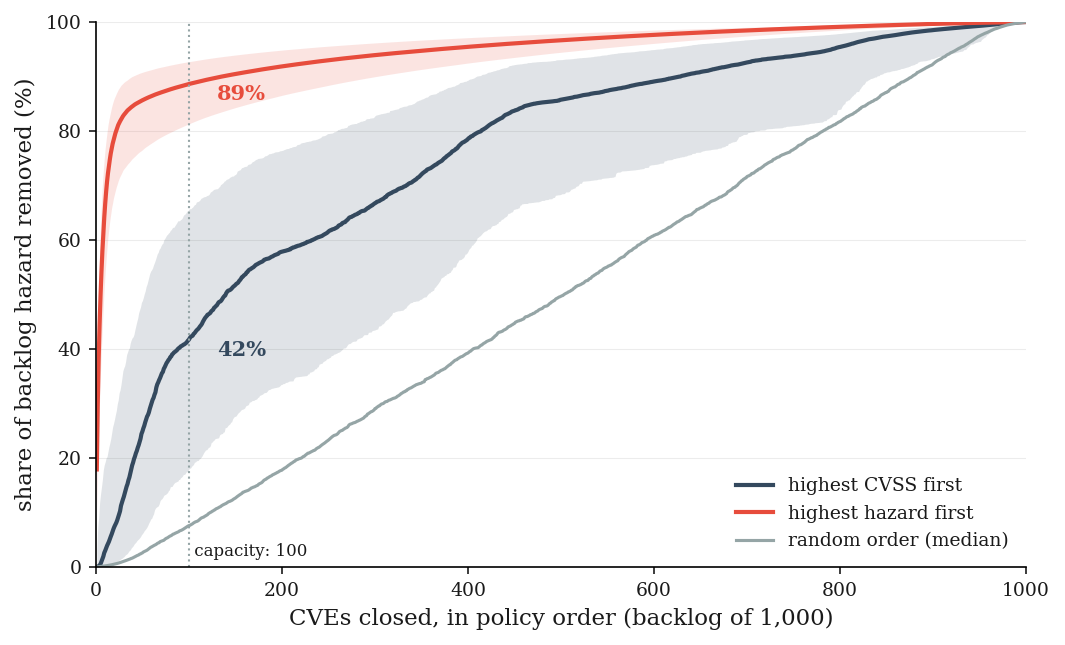

In [5]:
ks = np.arange(1, N + 1)
fig, ax = plt.subplots(figsize=(7.2, 4.4))

for curve, color, label in [(curve_cvss, DARK_BG, "highest CVSS first"),
                            (curve_hazard, ACCENT, "highest hazard first")]:
    lo, med, hi = np.percentile(curve, [5, 50, 95], axis=0)
    ax.plot(ks, 100 * med, color=color, lw=2, label=label)
    ax.fill_between(ks, 100 * lo, 100 * hi, color=color, alpha=0.15, lw=0)

ax.plot(ks, 100 * np.median(curve_random, axis=0), color=LIGHT_GRAY, lw=1.5,
        label="random order (median)")
ax.axvline(K, color=LIGHT_GRAY, lw=1, ls=":")
y_hz = 100 * np.median(curve_hazard[:, K - 1])
y_cv = 100 * np.median(curve_cvss[:, K - 1])
ax.annotate(f"{y_hz:.0f}%", (K, y_hz), xytext=(K + 30, y_hz - 3),
            color=ACCENT, fontsize=10, fontweight="bold")
ax.annotate(f"{y_cv:.0f}%", (K, y_cv), xytext=(K + 30, y_cv - 3),
            color=DARK_BG, fontsize=10, fontweight="bold")
ax.text(K, 2, f" capacity: {K}", color=PRIMARY, fontsize=8)

ax.set_xlabel(f"CVEs closed, in policy order (backlog of {N:,})")
ax.set_ylabel("share of backlog hazard removed (%)")
ax.set_xlim(0, N)
ax.set_ylim(0, 100)
ax.legend(frameon=False, loc="lower right")
ax.grid(axis="y", color="#E0E0E0", lw=0.5, alpha=0.6)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

The bands are the 5th-95th percentile across the simulated backlogs. The red
curve's knee is the concentration made visible: the sooner it bends, the
more of a backlog's hazard lives in its first findings, *if* you sort by
hazard. The grey line is random closure. How far the blue curve climbs above
grey is how much a severity ranking front-loads hazard; how far it stays
below red is what it leaves on the table. The width of its band shows how
much the outcome depends on which CVEs happen to be in your backlog.

## 5. Robustness -- split by CVE-ID year

The restriction to CNA-supplied CVSS scores (section 1) need not be neutral
across years: the printout below shows what share of EPSS-scored CVEs carry
a score before and after the cutoff year `RECENT`, and the recent share of
the scored set. If the scored set already leans recent, a recent-only rerun
overlaps heavily with the full one and is a weak check. So rerun everything
on the two disjoint periods, CVE-ID years before `RECENT` and from `RECENT`
on, next to the full set.

In [6]:
def summarize(min_year, max_year=9999, seed=42):
    s = pop.dropna(subset=["cvss_base"])
    s = s[(s.year >= min_year) & (s.year <= max_year)]
    h = exponential_hazard(s.epss.values)
    cv = s.cvss_base.values
    ns, Hs = len(s), h.sum()
    crit = cv >= 9
    srt = np.sort(h)[::-1]
    cum = np.cumsum(srt) / Hs
    rng = make_rng(seed)
    r_cv, r_hz, r_rd = np.empty(B), np.empty(B), np.empty(B)
    for b in range(B):
        idx = rng.choice(ns, N, replace=False)
        hh, cc = h[idx], cv[idx]
        total = hh.sum()
        o = np.lexsort((rng.random(N), -cc))[:K]
        r_cv[b] = hh[o].sum() / total
        r_hz[b] = np.sort(hh)[::-1][:K].sum() / total
        r_rd[b] = hh[:K].sum() / total
    kev = s.is_kev.values
    ep = s.epss.values
    return {
        "CVEs with CVSS": f"{ns:,}",
        "criticals: count / hazard": f"{crit.mean():.1%} / {h[crit].sum()/Hs:.1%}",
        "criticals with EPSS < 1%": f"{(s.epss.values[crit] < 0.01).mean():.1%}",
        "top 1% by EPSS: hazard": f"{cum[int(0.01*ns)-1]:.1%}",
        "KEV: count / hazard": f"{kev.mean():.1%} / {h[kev].sum()/Hs:.1%}",
        "KEV: share of EPSS sum": f"{ep[kev].sum()/ep.sum():.1%}",
        f"close {K}/{N} by CVSS (median)": f"{np.median(r_cv):.1%}",
        f"close {K}/{N} by hazard (median)": f"{np.median(r_hz):.1%}",
        f"close {K}/{N} at random (median)": f"{np.median(r_rd):.1%}",
    }

has_cvss = pop.cvss_base.notna()
recent = pop.year >= RECENT
print(f"EPSS-scored CVEs with a CVSS score: before {RECENT} {has_cvss[~recent].mean():.0%}, "
      f"{RECENT}+ {has_cvss[recent].mean():.0%}")
print(f"{RECENT}+ share of the scored set: {(has_cvss & recent).sum() / has_cvss.sum():.0%}")

comparison = pd.DataFrame({f"{MIN_YEAR}+": summarize(MIN_YEAR),
                           f"{MIN_YEAR}-{RECENT - 1}": summarize(MIN_YEAR, RECENT - 1),
                           f"{RECENT}+": summarize(RECENT)})
comparison

EPSS-scored CVEs with a CVSS score: before 2022 13%, 2022+ 65%
2022+ share of the scored set: 83%


,1999+,1999-2021,2022+
CVEs with CVSS,"139,274","23,606","115,668"
criticals: count / hazard,11.7% / 47.2%,10.6% / 45.4%,11.9% / 48.8%
criticals with EPSS < 1%,61.5%,20.0%,69.1%
top 1% by EPSS: hazard,69.1%,50.8%,70.5%
KEV: count / hazard,1.0% / 50.5%,3.6% / 66.0%,0.5% / 36.9%
KEV: share of EPSS sum,28.1%,44.3%,17.0%
close 100/1000 by CVSS (median),41.7%,43.5%,42.1%
close 100/1000 by hazard (median),88.6%,90.5%,85.3%
close 100/1000 at random (median),7.6%,9.0%,6.5%


Read the disjoint columns against each other: if the gap between the two
policies holds in both periods, it is not an artifact of either one. Group
shares (KEV, criticals) can move between periods even when the policy gap
holds.

## Takeaways

- Severity and likelihood are different axes. Criticals can carry a large
  share of the hazard as a *group* while most individual criticals are
  near-zero-EPSS (section 2 prints both), so a count of closed criticals
  says little about the likelihood removed.
- At the same reported output -- the same number of CVEs closed -- the two rankings can
  remove very different shares of the estimated hazard (section 3 prints the
  ratio and the spread across backlogs). That comparison is in EPSS's own
  terms: it shows how much a CVSS ranking gives up if EPSS is right, not
  whether EPSS is right.
- Without controls, as here, ranking by hazard is the same as ranking by
  EPSS; the transform changes the weights, not the order. Sums of EPSS are already additive (an expected
  count); hazard shares up-weight near-certain CVEs, so for high-EPSS groups
  they come out larger than EPSS-sum shares. Say which one you report.
- In arXiv:2607.24618 control effectiveness enters before the transform:
  each likelihood is multiplied by (1 - control effectiveness) for the
  controls aligned with the CVE's attack vector, and remediation actions are
  ranked by how much they reduce the aggregate hazard. With controls in, the
  hazard ranking is no longer the EPSS ranking. Public data provides only the
  uncontrolled term; control effectiveness (see
  [Measuring Control Effectiveness](01-measuring-control-effectiveness.ipynb))
  comes from your environment, and loss magnitude is a further step beyond
  the hazard.
- Scope: EPSS forecasts exploitation activity observed *anywhere*, so these
  are relative shares within a population, not an organisation's absolute
  event count.

---

*Data: EPSS scores by [FIRST.org](https://www.first.org/epss/); CVE metadata from
[CVEProject/cvelistV5](https://github.com/CVEProject/cvelistV5); KEV catalog
by [CISA](https://www.cisa.gov/known-exploited-vulnerabilities-catalog).
Hazard model: Shaffer & Voicu 2026,
[arXiv:2607.24618](https://arxiv.org/abs/2607.24618).*